# Titanic Competition

---

This notebook was made for the Titanic competition. The idea is to predict which passenger died, based on criteria like the gender, the class, the age for example.

Since it is a binary choice, we can use a classification algorithm: logistic regression, XGBoost classifier or some tree models.

> The data can be found on [Kaggle](https://www.kaggle.com/competitions/titanic/overview)

## Imports
---

All usefull import for the notebook.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import linear_model
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
)
from sklearn.preprocessing import (
    OneHotEncoder,
    MinMaxScaler,
)
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
)
from xgboost.sklearn import XGBClassifier

def data_preprocessing(df: pd.DataFrame, dropna: bool = True) -> pd.DataFrame:
    """
    Preprocessing function before applying any machine learning's models.
    It fill nan values using different technic depending on the data and do
    some feature engineering based on relationship between data:
    - create `family_member` column based on `SibSp` + `Parch`
    - create `isalone` column based on the number in `family_member` (if 0 -> isalone == 1)
    - create `title` column based on `Name` column
    - fillna using mode for `Embarked`
    - fillna using mean for `Fare`
    - fillna using median for `Age` per group of `title` and `Pclass`
    - Optional: fillna using the mode for ticket_num

    Args
    ----
    df : pandas.DataFrame
        A dataframe on which to apply the preprocessing
    dropna : optional, True
        If True, it drops all remaning nan values in the dataframe
        If False, it fills the remaining nan values from the column ticket_num using the mode

    Returns
    -------
    pandas.DataFrame : the preprocessed dataframe
    """
    df_preproc = df.copy()

    df_preproc.drop(columns="Cabin", inplace=True)

    # Fill with the most commun value
    df_preproc["Embarked"] = df_preproc["Embarked"].fillna(df_preproc["Embarked"].mode()[0])

    # Fill with the average value
    df_preproc["Fare"] = df_preproc["Fare"].fillna(df_preproc["Fare"].mean())

    # Create a new feature: family_member
    df_preproc["family_member"] = df_preproc["SibSp"] + df_preproc["Parch"]

    # Create a new feature: isalone
    df_preproc["isalone"] = (df_preproc["family_member"] == 0).astype(int)

    # Create a new feature: title
    df_preproc['title'] = df_preproc['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)

    df_preproc["Age"] = df_preproc["Age"].fillna(df_preproc.groupby(["title", "Pclass"])["Age"].transform("median"))
    df_preproc["Age"] = df_preproc["Age"].fillna(df_preproc["Age"].median())

    df_preproc["ticket_num"] = df_preproc["Ticket"].str.extract(r"(\d+)\s*$")[0].astype("Int64")
    df_preproc.drop(columns=["Ticket", "Name"], inplace=True)

    if dropna:
        df_preproc.dropna(how="any", inplace=True)
    else:
        df_preproc["ticket_num"] = df_preproc["ticket_num"].fillna(df_preproc["ticket_num"].mode()[0])
    return df_preproc

def plot_crosstab(df: pd.DataFrame, indexes: list[pd.Series]):
    ct = pd.crosstab(
        indexes,
        df["Survived"],
        normalize="index"
    )

    ct = ct.rename(columns={
        0: "Not survived",
        1: "Survived"
    })
    ct = (ct * 100).round(1)

    return ct.style \
    .format("{:.1f}%") \
    .background_gradient(cmap="RdYlGn", subset=["Survived"]) \

def plot_correlation_curve(df: pd.DataFrame, colnames: list) -> None:
    _, axes = plt.subplots(1, len(colnames), figsize=(20, 4))

    for ax, colname in zip(axes, colnames):
        df.groupby(colname)["Survived"].mean().plot(kind="bar", ax=ax, rot=0)
        ax.set_title(f"Survival rate by {colname}")
        ax.set_ylim(0, 1)

    plt.tight_layout()
    plt.show()

def plot_feature_importance(coefficients) -> None:
    feature_importance = pd.DataFrame(
        {
            "Feature": X_train.columns,
            "Importance": coefficients,
        }
    )
    feature_importance = feature_importance.sort_values(
        "Importance", ascending=True
    )

    feature_importance.plot(
        x="Feature", y="Importance", kind="barh", figsize=(12, 15)
    )
    plt.tight_layout()

def plot_model_comparison(df: pd.DataFrame, colnames: list[str]) -> None:
    comparison = {}

    for colname in colnames:
        comparison[colname[9:].replace("_", " ")] = (
            df[colname].value_counts(normalize=True)
                .reindex([0, 1], fill_value=0)
                .mul(100)
        )

    comparison = pd.DataFrame(comparison)
    comparison.index = ["Survived", "Died"]
    comparison.plot(
        kind="bar",
        figsize=(10, 5),
        rot=0,
    )

    plt.ylim(0, 100)
    plt.ylabel("Passengers (%)")
    plt.title("Comparison between all models")
    plt.legend(title="Model")
    plt.tight_layout()
    plt.show()

## Step 1 - Data preprocessing

---

The first step in our workflow for this competition is to open all the dataframe, explore their structure, and preprare them for modeling. This page is crucial, since the quality of the data has a direct impact on the **performance** and **reliability** of the model.

### 1.1 - Description of the data

---

We have 3 dataframes for this competition:
- ``train.csv`` - this dataframe can be used to build the machine learning model and train it. We have the label for each data (Survived).
- ``test.csv`` - this dataframe can be used to see if the model was trained correctly.
- ``gender_submission.csv`` - an example of submission file.  
  
  
  
| Variable | Definition | Key |
|------|-------|-------|
| PassengerId | The id of all passenger | - |
| Survived | If the person survived of not | 0 = No, 1 = Yes |
| Pclass | Ticket class | 1 = 1st, 2 = 2nd, 3 = 3rd |
| Name | The name of the passenger | - |
| Sex | The sex of the passenger | "male", "female" |
| Age | Age in years | - |
| SibSp | number of siblings / spouses aboard the Titanic | - |
| Parch | number of parents / children aboard the Titanic | - |
| Ticket | Ticket number | - |
| Fare | The price of the ticket | - |
| Cabin | Cabin number | - |
| Embarked | Port of embarkation | C = Cherbourg, Q = Queenstown, S = Southampton |

### 1.2 - Data Analysis

---

Before moving forward with modeling, it is essential to begin with a general inspection of the dataframes. This step ensures that the data are consistent, correctly formatted, and free from obvious errors. Checking aspects such as **units**, **data types** and **overall coherence** is critical, since any issues here can directly affect the quality of the model.

Once the dataframes have been reviewed, several preprocessing actions may be required including:
- adjust data types
- handling missing values
- converting columns
- identifying potential outliers.

In [2]:
df_train_raw = pd.read_parquet("../database/titanic/train.parquet")
df_test_raw = pd.read_parquet("../database/titanic/test.parquet")
gender = pd.read_parquet("../database/titanic/gender_submission.parquet")

df_train_raw.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,None,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,None,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,None,S


In [3]:
df_train_raw.info()
print("\n Sum nan values for df_train_raw: \n", df_train_raw.isna().sum())
df_test_raw.info()
print("\n Sum nan values for df_test_raw: \n", df_test_raw.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

 Sum nan values for df_train_raw: 
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          68

#### 1.2.1 - Feature Engineering and missing values

In general, when we have a magority of missing value for one column, we can delete the column(s) if it can not be filled using others.  
**For example:**

```python
data = {
    'rain': [0, 1, 1, 0, 0],
    'clouds': [0, np.nan, np.nan, np.nan, np.nan],
}

# Using the rule if rain == 1 --> clouds == 1
filled_data = {
    'rain': [0, 1, 1, 0, 0],
    'clouds': [0, 1, 1, 0, 0],
}
```

As we can see, here we have some columns with missing values. It is the case for ``Cabin``, with 687 missing values out of 889 and we do not have a way to fill them. So we can simply drop this column.

In [4]:
df_train = df_train_raw.drop(columns="Cabin")

For other columns that have a few missing values, we can also use different technics (here the main one):
- **mode**: value with the highest occurence
- **mean**: the average of all values of the column (can be use for temperature for example)
- **median**: the median of all values of the column (can be used for ages for example)

For the column ``Embarked``, we can us the value that appeared the most using mode.

In [5]:
df_train["Embarked"] = df_train["Embarked"].fillna(df_train["Embarked"].mode()[0])

In [6]:
print("train: \n", df_train.isna().sum())

train: 
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         0
dtype: int64


As we can see, the column ``Ticket`` contains 2 parts: string and integer. Based on this, we can create ``ticket_prefix`` and ``ticket_num``. From the column ``Name``, we can also extract the ``Title`` for each passenger. We can use ``SibSp`` and ``Parch`` to create a new column ``family_member`` and ``solo_traveller`` by doing:  
- ``family_member`` = ``SibSp`` + ``Parch``
- ``solo_traveller`` = 1 where ``family_member`` = 0 else 0

In [ ]:
# Create a new feature: family_member
df_train["family_member"] = df_train["SibSp"] + df_train["Parch"]

# Create a new feature: isalone
df_train["isalone"] = (df_train["family_member"] == 0).astype(int)

# Create a new feature: title
df_train['title'] = df_train['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)

# Create a new feature: ticket_num
df_train["ticket_num"] = df_train["Ticket"].str.extract(r"(\d+)\s*$")[0].astype("Int64")

# Delete the columns Ticket and Name since we have already extracted the information we need from them
df_train = df_train.drop(columns=["Ticket", "Name"])
df_train.dropna(how="any", inplace=True)
df_train.isna().sum()

To fill the age values, we can use the ``Title``, the ``Pclass`` and compute the median value for the age. This allows the fill the age by group of social rank. By checking the historical data for the first few passenger, we can see that this way is pretty accurate:

| Name | Filled age | Real age |
|------|------|------|
| Moran, Mr. James| 26 years | 28 years |
| Emir, Mr. Farred Chehab | 26 years | 26 years |
| O'Dwyer, Miss. Ellen "Nellie" | 18 years | 22 years |
| Todoroff, Mr. Lalio | 26 years | 23 years |

In [8]:
df_train["Age"] = df_train["Age"].fillna(df_train.groupby(["title", "Pclass"])["Age"].transform("median"))
df_train["Age"] = df_train["Age"].fillna(df_train["Age"].median())

Once we preprocessed the data, handled missing values and extract informations from columns, we can check if their is any relationship between features.

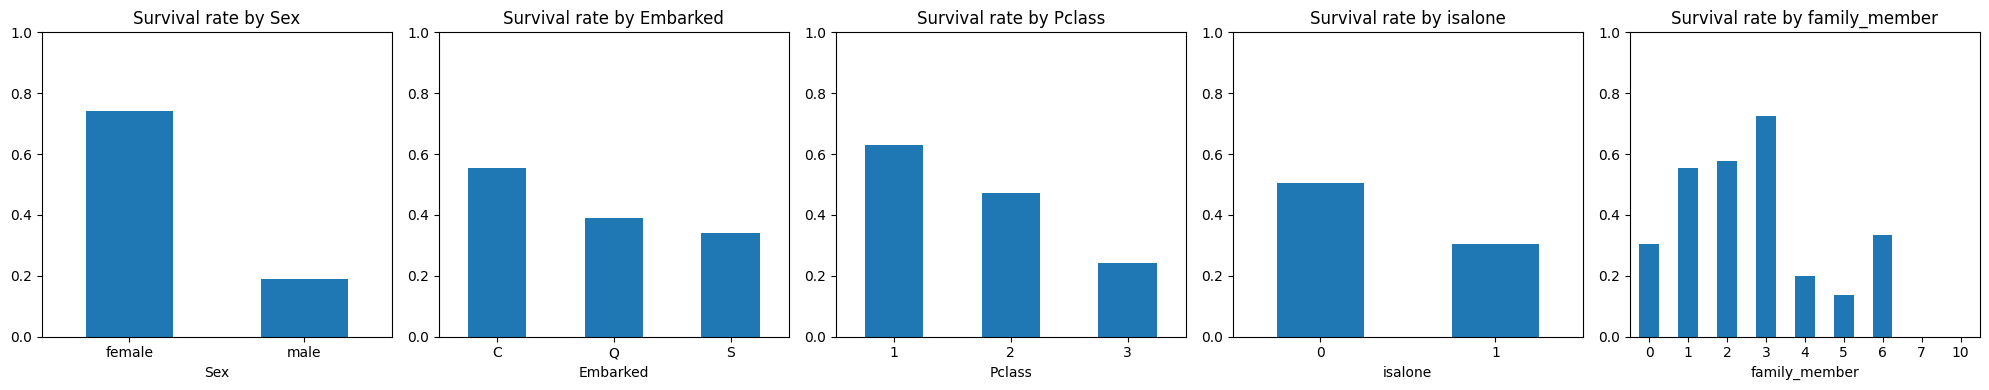

In [9]:
colnames = ["Sex", "Embarked", "Pclass", "isalone", "family_member"]
plot_correlation_curve(df_train, colnames)

A good way to check is to plot cross-correlation matrix.

In [10]:
plot_crosstab(df_train, [df_train["family_member"], df_train["Sex"]])
plot_crosstab(df_train, [df_train["Embarked"], df_train["Sex"]])
plot_crosstab(df_train, [df_train["Pclass"]])
plot_crosstab(df_train, [df_train["isalone"], df_train["Sex"]])

We apply the same preprocessing step to the ``df_test`` using the ``data_preprocessing`` function that summarizes all steps presented before.

In [12]:
df_test = data_preprocessing(df_test_raw, False)

## Step 2 - Encoding and scaling

---

### 2.1 - Set up the data

---

In this step, we will separate the train dataset into 2 datasets: train and test. The `df_train` contains the column `Survived`, which is the label telling if a passenger survived or not. It is the target value the model has to predict. So we first have to separate the features from the target. Then we can split into the 2 datasets, using 85% of the values as a train dataset and the rest for the test.

In [ ]:
features = df_train.drop(columns="Survived")
target = df_train["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.15,
    random_state=42
)

X_train, y_train = df_train.drop(columns="Survived"), df_train["Survived"]

### 2.2 - Encoding and scaling

---

Before building the classification model, we need to transform the categorical variable `Sex`, `Embarked`. These columns currently contain string values but we require numerical inputs.

We need an encoder that does not create an order. We do not want, for example `female=1` and `male=2` because there is no reason the feature `male` weights more than female. We can use `OneHotEncoder`. We already check that `title`, `Embarked` and `Sex` contain unique values "S", "C", "Q" and "male", "female".

> Note: we apply fit_transform on `X_train` first then transform on `X_test` to prevent data leakage.

In [14]:
enc = OneHotEncoder(handle_unknown="ignore")

columns2encode = ["Sex", "Embarked", "title"]

X_train_encoded = enc.fit_transform(X_train[columns2encode])
X_test_encoded = enc.transform(X_test[columns2encode])
X_result_encoded = enc.transform(df_test[columns2encode])

train_encoded_df = pd.DataFrame(
    X_train_encoded.toarray(),
    columns=enc.get_feature_names_out(columns2encode),
    index=X_train.index
)
test_encoded_df = pd.DataFrame(
    X_test_encoded.toarray(),
    columns=enc.get_feature_names_out(columns2encode),
    index=X_test.index
)
result_encoded_df = pd.DataFrame(
    X_result_encoded.toarray(),
    columns=enc.get_feature_names_out(columns2encode),
    index=df_test.index
)

X_train = pd.concat(
    [X_train.drop(columns=columns2encode), train_encoded_df],
    axis=1
)
X_test = pd.concat(
    [X_test.drop(columns=columns2encode), test_encoded_df],
    axis=1
)
X_result = pd.concat(
    [df_test.drop(columns=columns2encode), result_encoded_df],
    axis=1
)

In [65]:
df_train["ticket_num"].max()

np.int64(3101317)

Now, the idea is to scale the data to prevent some features, like "Embarked_C", with values within {0, 1} does not have any weight compared to "ticket_num" (in a range [3, 3101317]).
We will use MinMaxScaler

In [15]:
min_max_scale = MinMaxScaler()

X_train_scaled = min_max_scale.fit_transform(X_train)
X_test_scaled = min_max_scale.fit_transform(X_test)
X_result_scaled = min_max_scale.fit_transform(X_result)

## Step 3 - Classification models

---

We have to determine if a passenger survived or not. So we expect the result to b 0 or 1. For this type of task, we can classification models like the `LogisticRegression`, `RandomForestRegressor` or `XGBClassifier`.  
I will present these 3 models with a little part about optimisation (using `GridSearchCV` and `RandomizedSearchCV`) to see if there is a model better than the other one.

### 3.1 - LogisticRegression

#### General model

In [16]:
logic_reg = linear_model.LogisticRegression()
logic_reg.fit(X_train_scaled, y_train, sample_weight=None)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [17]:
logic_reg.fit(X_train_scaled, y_train, sample_weight=None)

print("Score on train dataset:", logic_reg.score(X_train_scaled, y_train))
print("Score on test dataset:", logic_reg.score(X_test_scaled, y_test))

Score on train dataset: 0.8376550169109357
Score on test dataset: 0.7921348314606742


In [18]:
y_pred = logic_reg.predict(X_test_scaled)
probs = logic_reg.predict_proba(X_test_scaled)

In [19]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.84      0.82       102
           1       0.77      0.72      0.75        76

    accuracy                           0.79       178
   macro avg       0.79      0.78      0.79       178
weighted avg       0.79      0.79      0.79       178



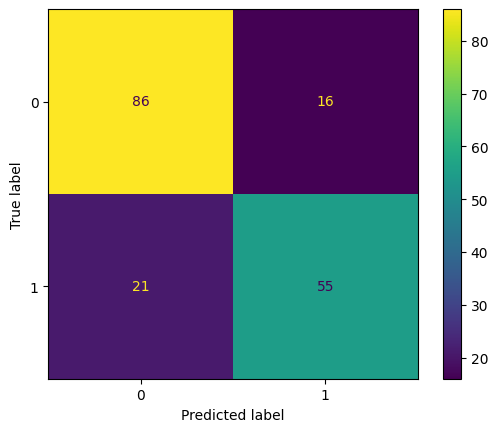

In [20]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=logic_reg.classes_)

#### Optimisation

In [21]:
parameters = {
    "C": np.arange(0.5, 2, 0.2),
    "max_iter": [50, 100, 500, 1000],
}

gridsearch = GridSearchCV(logic_reg, parameters)
gridsearch.fit(X_train_scaled, y_train)

,estimator,LogisticRegression()
,param_grid,"{'C': array([0.5, 0....5, 1.7, 1.9]), 'max_iter': [50, 100, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [22]:
logic_reg_opt = linear_model.LogisticRegression(**gridsearch.best_params_)
logic_reg_opt.fit(X_train_scaled, y_train, sample_weight=None)

print("Score on train dataset:", logic_reg_opt.score(X_train_scaled, y_train))
print("Score on test dataset:", logic_reg_opt.score(X_test_scaled, y_test))

Score on train dataset: 0.8410372040586246
Score on test dataset: 0.7921348314606742


In [23]:
y_pred_lreg = logic_reg_opt.predict(X_test_scaled)
probs_lreg = logic_reg_opt.predict_proba(X_test_scaled)

In [24]:
print(classification_report(y_test, y_pred_lreg))

              precision    recall  f1-score   support

           0       0.80      0.84      0.82       102
           1       0.77      0.72      0.75        76

    accuracy                           0.79       178
   macro avg       0.79      0.78      0.79       178
weighted avg       0.79      0.79      0.79       178



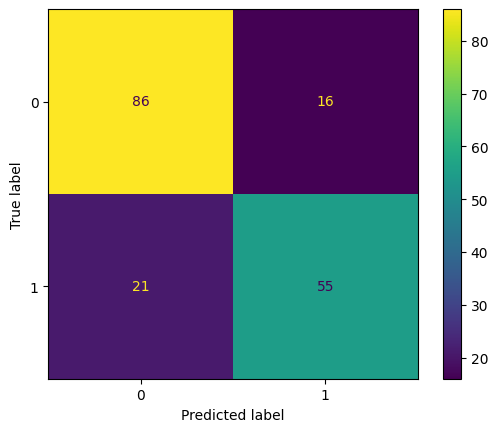

In [25]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lreg, display_labels=logic_reg_opt.classes_)

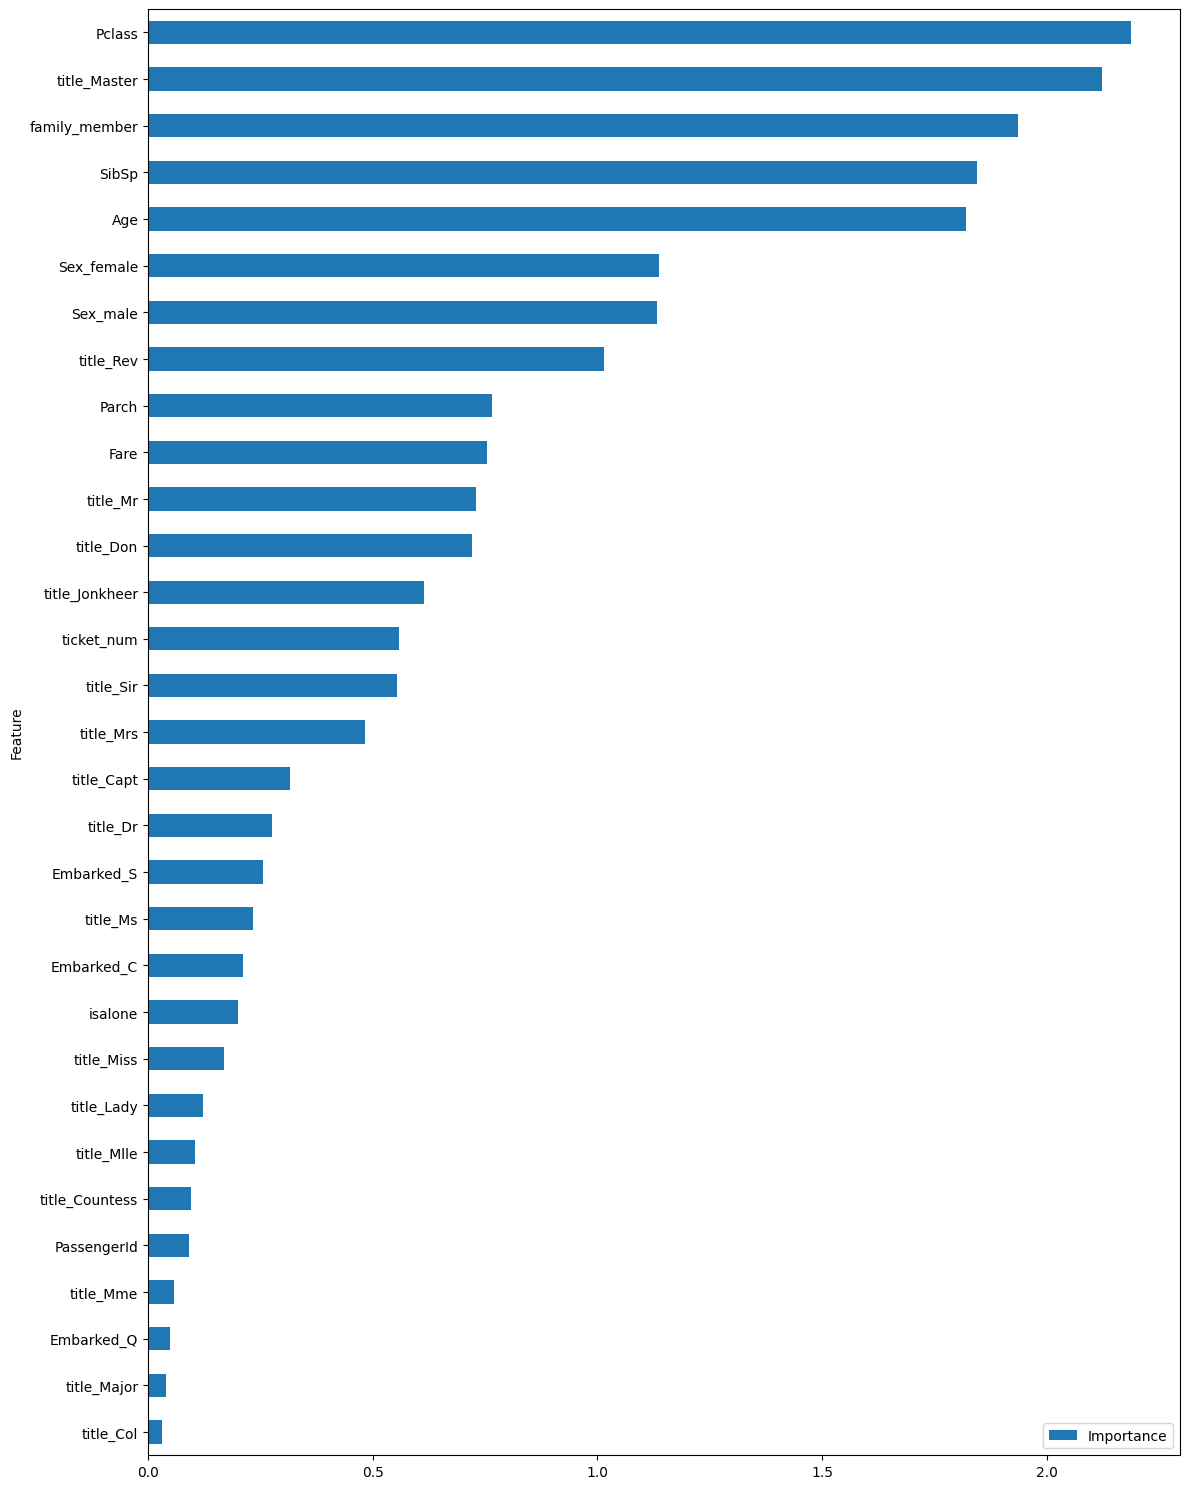

In [26]:
plot_feature_importance(np.abs(logic_reg_opt.coef_)[0, :])

#### Apply the model on df_test

In [27]:
y_pred_result_logic_reg = logic_reg_opt.predict(X_result_scaled)
probs_result_logic_reg = logic_reg_opt.predict_proba(X_result_scaled)

### 3.2 - Random Forest

#### General model

In [28]:
rdm_forest = RandomForestClassifier()
rdm_forest.fit(X_train_scaled, y_train, sample_weight=None)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [29]:
print("Score on train dataset:", rdm_forest.score(X_train_scaled, y_train))
print("Score on test dataset:", rdm_forest.score(X_test_scaled, y_test))

Score on train dataset: 1.0
Score on test dataset: 0.8876404494382022


In [30]:
y_pred_rdm = rdm_forest.predict(X_test_scaled)
probs_rdm = rdm_forest.predict_proba(X_test_scaled)

In [31]:
print(classification_report(y_test, y_pred_rdm))

              precision    recall  f1-score   support

           0       0.86      0.96      0.91       102
           1       0.94      0.79      0.86        76

    accuracy                           0.89       178
   macro avg       0.90      0.88      0.88       178
weighted avg       0.89      0.89      0.89       178



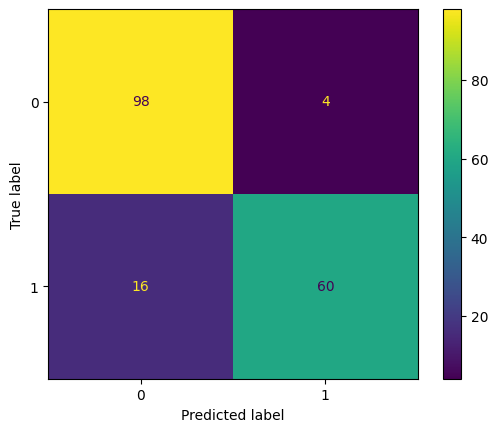

In [32]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rdm, display_labels=rdm_forest.classes_)

#### Optimization

In [ ]:
rf_params = {
    "n_estimators": [200, 400],
    "max_depth": [3, 4, 5, 6, 8],
    "min_samples_leaf": [1, 3, 5, 10],
    "max_features": ["sqrt", 0.5],
    "random_state": [0],
}

gridsearch = GridSearchCV(rdm_forest, rf_params)
gridsearch.fit(X_train_scaled, y_train)

,estimator,RandomForestClassifier()
,param_grid,"{'criterion': ['gini', 'entropy', ...], 'n_estimators': array([ 50, 100, 150, 200]), 'random_state': [0]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,np.int64(150)


In [34]:
rdm_forest_opt = RandomForestClassifier(**gridsearch.best_params_)
rdm_forest_opt.fit(X_train_scaled, y_train, sample_weight=None)

print("Score on train dataset:", rdm_forest_opt.score(X_train_scaled, y_train))
print("Score on test dataset:", rdm_forest_opt.score(X_test_scaled, y_test))

Score on train dataset: 1.0
Score on test dataset: 0.8932584269662921


In [35]:
y_pred_rdm_opt = rdm_forest_opt.predict(X_test_scaled)
probs_rdm_opt = rdm_forest_opt.predict_proba(X_test_scaled)

In [ ]:
print(classification_report(y_test, y_pred_rdm_opt))

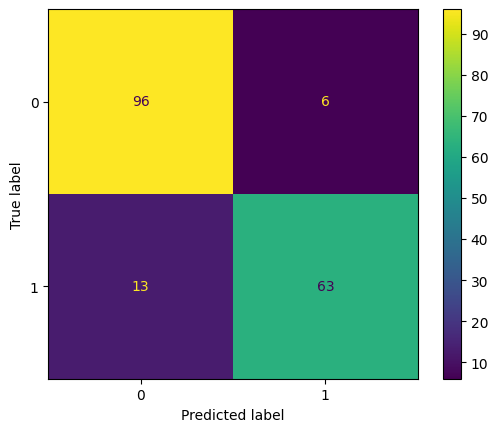

In [36]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rdm_opt, display_labels=rdm_forest_opt.classes_)

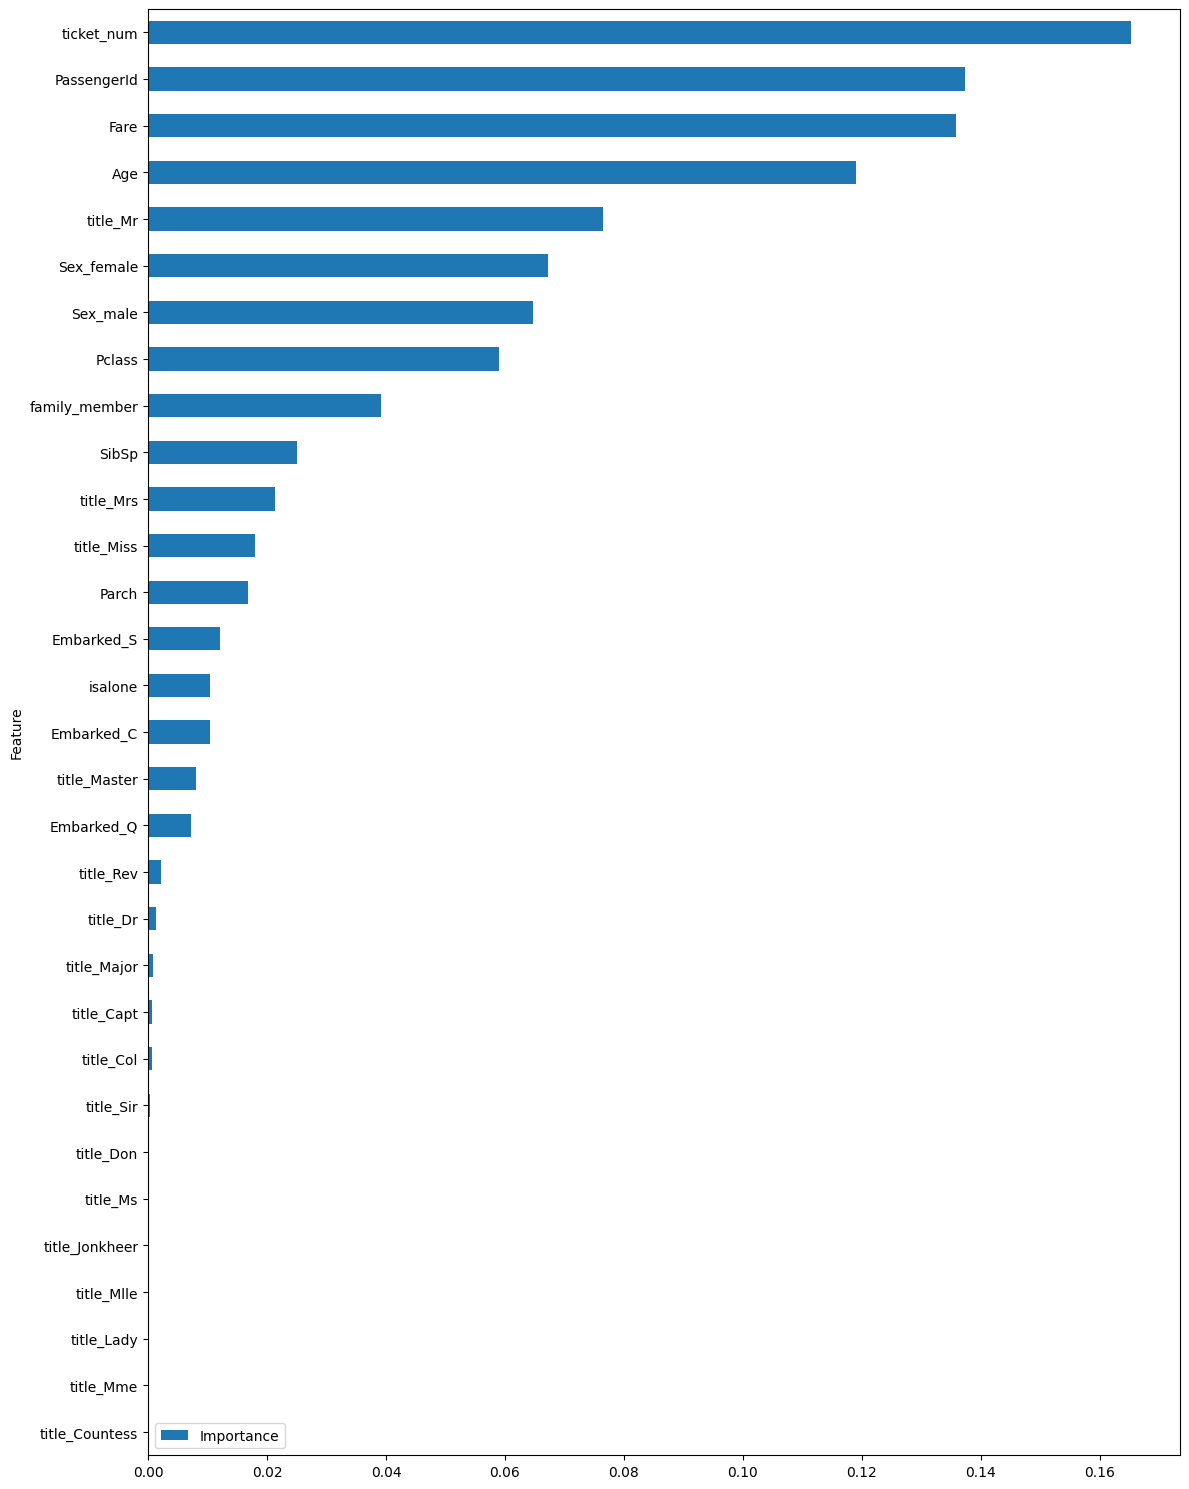

In [37]:
plot_feature_importance(rdm_forest_opt.feature_importances_)

#### Apply the model on df_test

In [39]:
y_pred_result_rdm_forest = rdm_forest_opt.predict(X_result_scaled)
probs_result_rdm_forest = rdm_forest_opt.predict_proba(X_result_scaled)

### 3.3 - XGBoost

#### General model

In [41]:
xgboost = XGBClassifier()
xgboost.fit(X_train_scaled, y_train, sample_weight=None)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [42]:
print("Score on train dataset:", xgboost.score(X_train_scaled, y_train))
print("Score on test dataset:", xgboost.score(X_test_scaled, y_test))

Score on train dataset: 1.0
Score on test dataset: 0.9157303370786517


In [43]:
y_pred_xgb = xgboost.predict(X_test_scaled)
probs_xgb = xgboost.predict_proba(X_test_scaled)

In [44]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.92      0.93      0.93       102
           1       0.91      0.89      0.90        76

    accuracy                           0.92       178
   macro avg       0.91      0.91      0.91       178
weighted avg       0.92      0.92      0.92       178



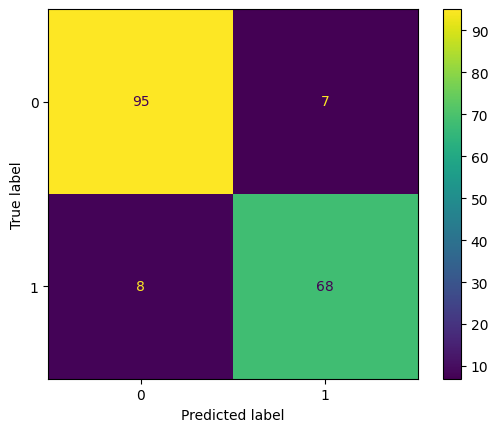

In [45]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb, display_labels=rdm_forest.classes_)

#### Optimisation

In [ ]:
xgb_params = {
    "max_depth": [2, 3, 4],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "n_estimators": [200, 400, 600],
    "subsample": [0.7, 0.9],
    "colsample_bytree": [0.7, 1.0],
    "min_child_weight": [1, 3, 5],
    "reg_lambda": [1, 5, 10],
    "random_state": [0],
}

gridsearch = RandomizedSearchCV(xgboost, xgb_params, n_iter=100)
gridsearch.fit(X_train_scaled, y_train)

,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'eval_metric': ['logloss'], 'learning_rate': array([0.01, ..., 0.97, 0.99]), 'max_depth': [1, 2, ...], 'n_estimators': [200, 250, ...]}"
,scoring,None
,n_jobs,None
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [50]:
xgboost_opt = XGBClassifier(**gridsearch.best_params_)
xgboost_opt.fit(X_train_scaled, y_train, sample_weight=None)

print("Score on train dataset:", xgboost_opt.score(X_train_scaled, y_train))
print("Score on test dataset:", xgboost_opt.score(X_test_scaled, y_test))

Score on train dataset: 0.9661781285231116
Score on test dataset: 0.8539325842696629


In [ ]:
y_pred_xgb_opt = xgboost_opt.predict(X_test_scaled)
probs_xgb_opt = xgboost_opt.predict_proba(X_test_scaled)

In [ ]:
print(classification_report(y_test, y_pred_xgb_opt))

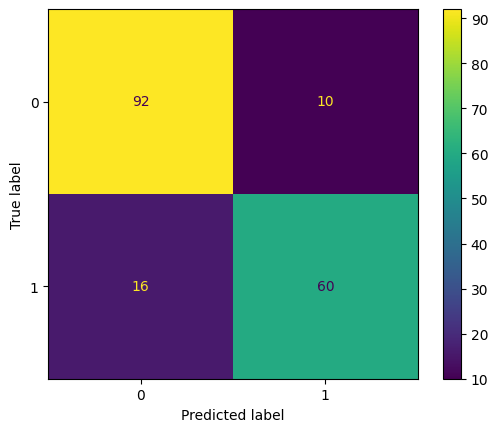

In [52]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=xgboost_opt.classes_)

#### Apply the model on df_test

In [ ]:
y_pred_result_xgboost = xgboost_opt.predict(X_result_scaled)
probs_result_xgboost = xgboost_opt.predict_proba(X_result_scaled)

## Step 4 - Quick comparison

---



In [61]:
output = pd.DataFrame(
    {
        'PassengerId': df_test.PassengerId,
        'Survived_logic_reg': y_pred_result_logic_reg,
        'Survived_rdm_forest': y_pred_result_rdm_forest,
        'Survived_xgboost': y_pred_result_xgboost,
    }
)

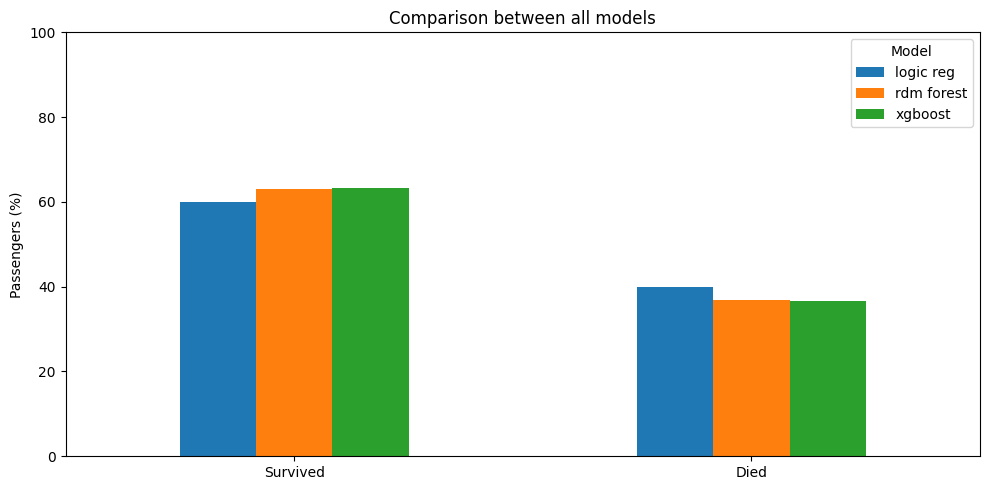

In [ ]:
colnames = [
    "Survived_logic_reg",
    "Survived_rdm_forest",
    "Survived_xgboost",
]

plot_model_comparison(output, colnames)